# C²LUT — ダミーデータで色補正を可視化する

**人工データ → 学習 → 未知の光源・反射率で評価 → nanobind 推論 → 保存・再読込み**を、
この Notebook だけで実行します。`src/c2lut` の公開 API を再利用し、学習や補間の実装は複製しません。

| 見るもの | 確認すること |
|---|---|
| データの分布 | 光源と反射率の両方で学習・検証・試験を分離できているか |
| 学習曲線 | 検証誤差が低下し、検証データで最良の重みを選べているか |
| 色差・色パッチ | 初期モデル、固定 3×3 行列、学習後 C²LUT がどう違うか |
| 混合重み・LUT 断面 | 光源によって変換が変わるか |
| 保存と推論の照合 | PyTorch と C++ の結果、保存前後の結果が一致するか |

**データの意味：** ガウス関数で作った人工センサー・人工等色関数と、人工光源・反射率を使います。
教師は **XYZ 相当の合成値**であり、実測 CIE 等色関数や標準 D65 の分光分布は使っていません。
ΔE はこの合成座標系での比較指標です。実在するカメラの測色精度や論文の実験値の再現は意味しません。

## 実行方法（Linux）

リポジトリのルートから次を実行し、Jupyter の **Restart Kernel and Run All Cells** を選びます。
Python 3.12、CPU、1 スレッド、1,600 更新を既定としています。GPU と外部データは不要です。

```bash
uv sync --locked --extra notebook
uv run --locked --extra notebook jupyter lab notebooks/synthetic_color_correction.ipynb
```

図と実行結果は Notebook に埋め込み済みです。再実行時は `artifacts/notebook/` に
データ・モデル・指標・PNG を保存します。下の設定セルで乱数 seed と更新回数を変更できます。

In [1]:
from __future__ import annotations

import json
import os
import platform
from dataclasses import asdict
from importlib.metadata import version
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure
from numpy.typing import NDArray

from c2lut import C2LUT, ModelConfig, ModelParameters, _native
from c2lut.color import delta_e76, xyz_to_lab
from c2lut.data import make_synthetic_splits
from c2lut.evaluation import color_metrics, fit_fixed_ccm, predict_dataset
from c2lut.training import TrainableC2LUT, TrainingConfig, fit

FloatArray = NDArray[np.float64]
SEED = 42
TRAINING_STEPS = 1600
torch.set_num_threads(1)
plt.switch_backend("Agg")

working_directory = Path.cwd().resolve()
project_root = next(
    path
    for path in (working_directory, *working_directory.parents)
    if (path / "pyproject.toml").is_file() and (path / "src" / "c2lut").is_dir()
)
artifact_dir = Path(
    os.environ.get("C2LUT_NOTEBOOK_OUTPUT", str(project_root / "artifacts" / "notebook"))
)
figure_dir = artifact_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_files: list[str] = []

palette = {"initial": "#8391A5", "fixed_ccm": "#D28A24", "trained": "#137B75"}
labels = {"initial": "Initial LUT", "fixed_ccm": "Fixed 3x3 CCM", "trained": "Trained C2LUT"}
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.18,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "legend.frameon": False,
    }
)


def show_figure(figure: Figure, filename: str) -> None:
    """Save a portable PNG and embed it without relying on an interactive backend."""
    path = figure_dir / filename
    figure.savefig(path, dpi=130, bbox_inches="tight", facecolor="white")
    relative = path.relative_to(artifact_dir).as_posix()
    if relative not in figure_files:
        figure_files.append(relative)
    display(Image(filename=str(path)))
    plt.close(figure)


versions = {
    "Python": platform.python_version(),
    "NumPy": np.__version__,
    "PyTorch": torch.__version__,
    "Matplotlib": version("matplotlib"),
    "nanobind": "C++ extension loaded",
}
display(Markdown(" | ".join(f"**{name}** {value}" for name, value in versions.items())))

**Python** 3.12.14 | **NumPy** 2.5.4 | **PyTorch** 2.15.0+cpu | **Matplotlib** 3.11.2 | **nanobind** C++ extension loaded

## 1. 人工データと分割の確認

48 光源と 240 反射率から、分光積分でカメラ RGB と教師 XYZ 相当値を生成します。
光源 ID と反射率 ID を、それぞれ約 60% / 20% / 20% に分けます。
使うのは各区分の直積だけで、区分をまたぐ組合せは使いません。
同じ光源または同じ反射率が別の区分へ混ざっていないことを、ID で検証します。

左図は光源の **カメラ rg 色度**、右図は反射率ごとの教師 Y の分布です。
カメラ rg は CIE xy 色度ではありません。教師は同じ反射率なら光源によらず共通です。

| Split | Illuminants | Reflectances | Pairs |
|---|---:|---:|---:|
| train | 28 | 144 | 4032 |
| validation | 10 | 48 | 480 |
| test | 10 | 48 | 480 |

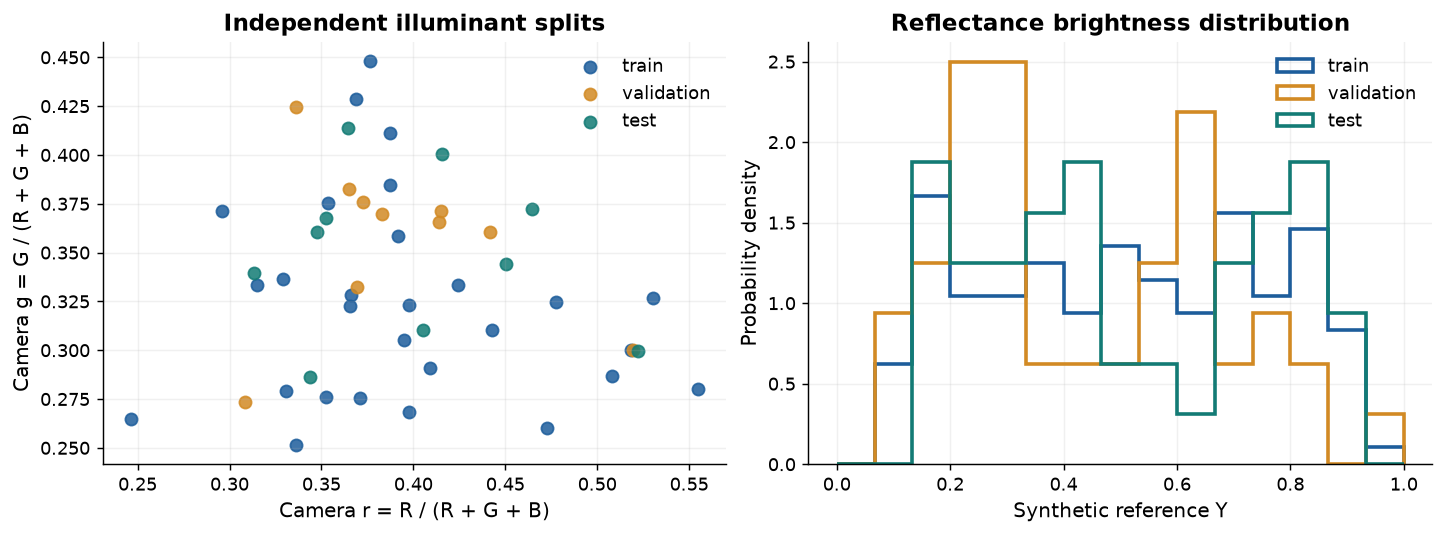

In [2]:
splits = make_synthetic_splits(seed=SEED, n_illuminants=48, n_reflectances=240)
datasets = {name: getattr(splits, name) for name in ("train", "validation", "test")}
for attribute in ("illuminant_ids", "reflectance_ids"):
    id_sets = [set(getattr(dataset, attribute)) for dataset in datasets.values()]
    assert all(left.isdisjoint(right) for left, right in combinations(id_sets, 2))
for name, dataset in datasets.items():
    dataset.save(artifact_dir / f"{name}.npz")

rows = ["| Split | Illuminants | Reflectances | Pairs |", "|---|---:|---:|---:|"]
for name, dataset in datasets.items():
    illuminants, reflectances, _ = dataset.raw.shape
    rows.append(f"| {name} | {illuminants} | {reflectances} | {illuminants * reflectances} |")
display(Markdown("\n".join(rows)))

split_colors = {"train": "#1D5D9B", "validation": "#D28A24", "test": "#137B75"}
figure, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for name, dataset in datasets.items():
    rg = dataset.white_points[:, :2] / dataset.white_points.sum(axis=1, keepdims=True)
    axes[0].scatter(rg[:, 0], rg[:, 1], s=45, color=split_colors[name], label=name, alpha=0.85)
    axes[1].hist(
        dataset.xyz[0, :, 1],
        bins=np.linspace(0, 1, 16),
        density=True,
        histtype="step",
        linewidth=2,
        color=split_colors[name],
        label=name,
    )
axes[0].set(
    xlabel="Camera r = R / (R + G + B)",
    ylabel="Camera g = G / (R + G + B)",
    title="Independent illuminant splits",
)
axes[0].legend()
axes[1].set(
    xlabel="Synthetic reference Y",
    ylabel="Probability density",
    title="Reflectance brightness distribution",
)
axes[1].legend()
show_figure(figure, "01_data_splits.png")

## 2. 小規模 C²LUT の学習

CPU で扱いやすい **格子 9³・階数 4・基底 4・MLP 隠れ幅 32** を使います。
論文の規模（格子 65³・階数 17・基底 12）とは別の、動作確認向け設定です。
初期 LUT は恒等変換です。基底の対称性を崩す平均ゼロの摂動を加え、光源依存の学習を可能にします。

学習には train、最良モデルの選択には validation だけを使います。
**test は更新にもモデル選択にも使いません。** `fit` は最良の検証 ΔE76 の重みを復元して返します。

In [3]:
model_config = ModelConfig(grid_size=9, rank=4, num_bases=4, hidden_features=32)
initial_parameters = ModelParameters.identity(model_config, seed=SEED, perturbation=0.03)
initial_model = C2LUT(initial_parameters)
trainable = TrainableC2LUT(initial_parameters)
training_config = TrainingConfig(
    steps=TRAINING_STEPS,
    learning_rate=0.003,
    min_learning_rate=1e-6,
    batch_illuminants=8,
    samples_per_illuminant=64,
    smoothness_weight=0.1,
    validation_interval=10,
    seed=SEED,
)
training_result = fit(trainable, splits.train, validation=splits.validation, config=training_config)
trained_model = C2LUT(trainable.export_parameters())
display(
    Markdown(
        f"**最良の更新：{training_result.best_step:,} / {TRAINING_STEPS:,}**　"
        f"検証 ΔE76：{training_result.initial_delta_e76:.3f} → "
        f"**{training_result.best_delta_e76:.3f}**　"
        f"パラメータ数：{trained_model.parameters.parameter_count:,}"
    )
)

**最良の更新：1,430 / 1,600**　検証 ΔE76：20.602 → **2.096**　パラメータ数：1,113

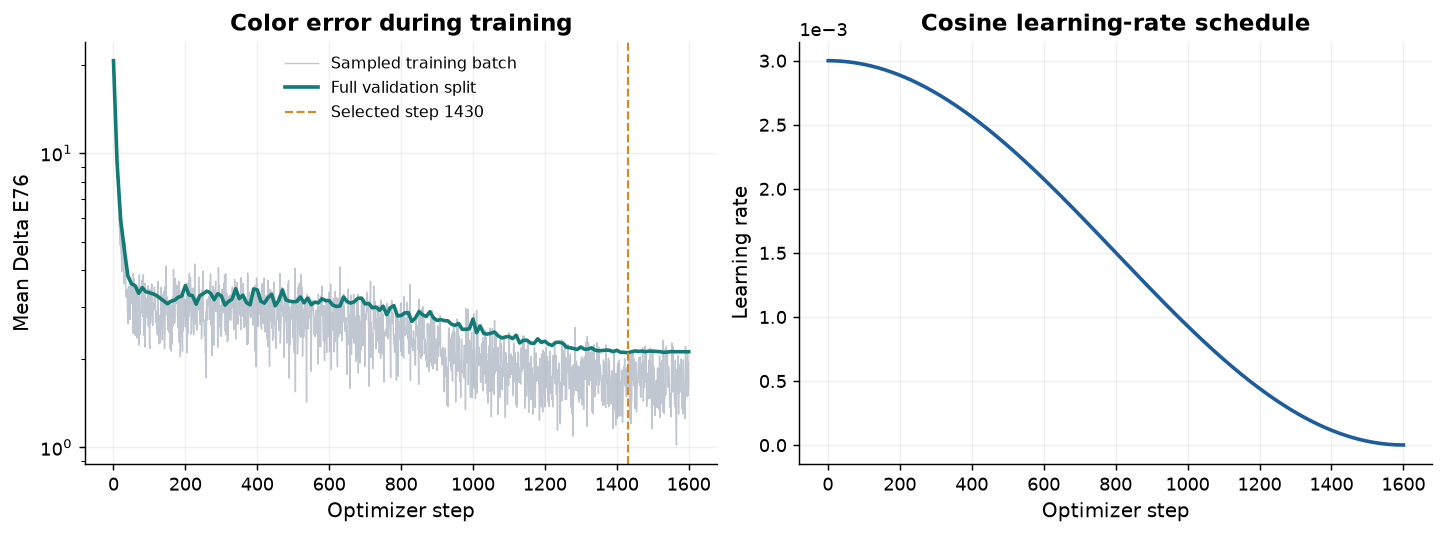

In [4]:
history = training_result.history
validation_records = [record for record in history if record.validation_delta_e76 is not None]
figure, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(
    [record.step for record in history],
    [record.color_loss for record in history],
    color="#8391A5",
    alpha=0.5,
    linewidth=0.8,
    label="Sampled training batch",
)
axes[0].plot(
    [0, *[record.step for record in validation_records]],
    [
        training_result.initial_delta_e76,
        *[record.validation_delta_e76 for record in validation_records],
    ],
    color="#137B75",
    linewidth=2,
    label="Full validation split",
)
axes[0].axvline(
    training_result.best_step,
    color="#D28A24",
    linestyle="--",
    linewidth=1.2,
    label=f"Selected step {training_result.best_step}",
)
axes[0].set(
    xlabel="Optimizer step",
    ylabel="Mean Delta E76",
    yscale="log",
    title="Color error during training",
)
axes[0].legend(fontsize=9)
axes[1].plot(
    [record.step for record in history],
    [record.learning_rate for record in history],
    color="#1D5D9B",
    linewidth=2,
)
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[1].set(xlabel="Optimizer step", ylabel="Learning rate", title="Cosine learning-rate schedule")
show_figure(figure, "02_learning_curves.png")

## 3. 未知の光源・反射率で比較する

3 方式を、同じ test の全 480 組で評価します。

- **Initial LUT**：学習前の恒等 LUT。白色化したカメラ RGB を XYZ 相当値として出力する初期状態です。
- **Fixed 3×3 CCM**：train だけで最小二乗推定した、光源に依存しない色補正行列です。
- **Trained C²LUT**：検証データで選択した重みを NumPy へ書き出し、nanobind の C++ 補間で推論します。

数値評価には、出力を切り詰めずに使います。平均だけでなく、95 パーセンタイルと光源ごとの誤差も確認します。
ECDF は「横軸の色差以下に収まる試験組の割合」で、同じ割合なら左にあるほど誤差が小さいことを示します。

| Method | XYZ RMSE | Mean ΔE76 | P95 ΔE76 | Mean ΔE00 | Mean angle (°) |
|---|---:|---:|---:|---:|---:|
| Initial LUT | 0.05055 | 18.425 | 43.640 | 9.554 | 4.107 |
| Fixed 3x3 CCM | 0.01815 | 2.757 | 6.879 | 1.552 | 0.859 |
| Trained C2LUT | 0.01773 | 2.155 | 6.149 | 1.243 | 0.625 |

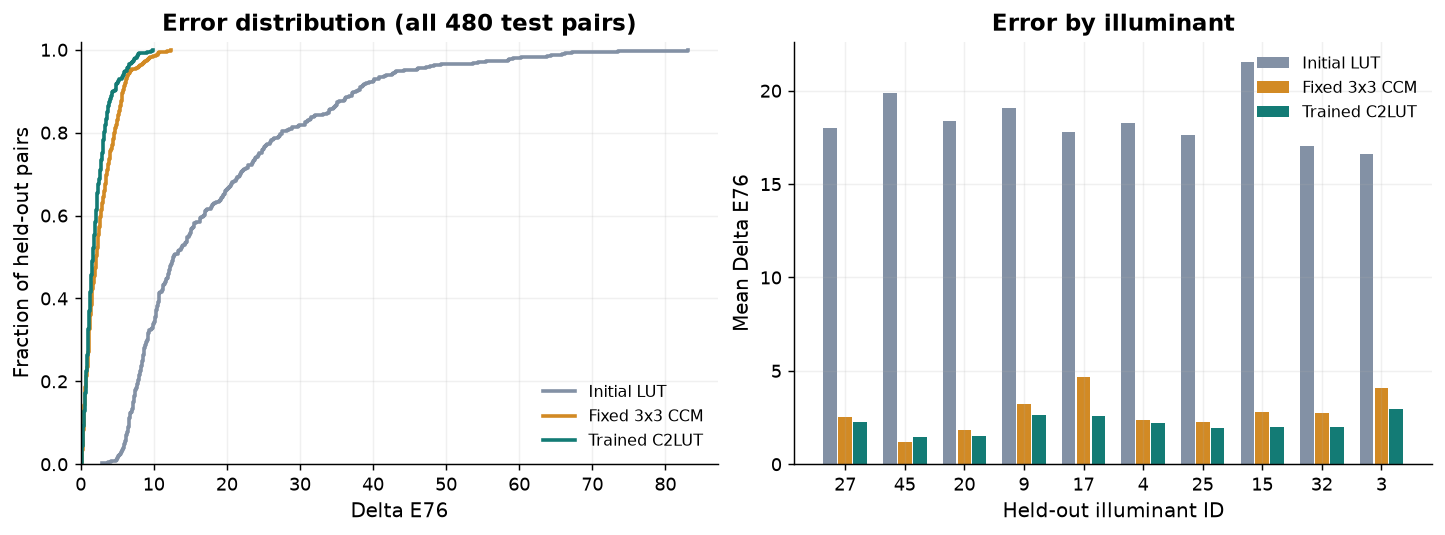

In [5]:
fixed_ccm = fit_fixed_ccm(splits.train)
test_balanced = splits.test.raw / splits.test.white_points[:, None, :]
predictions = {
    "initial": predict_dataset(initial_model, splits.test),
    "fixed_ccm": test_balanced @ fixed_ccm,
    "trained": predict_dataset(trained_model, splits.test),
}
metrics = {
    name: color_metrics(prediction, splits.test.xyz) for name, prediction in predictions.items()
}
target_lab = xyz_to_lab(splits.test.xyz)
errors = {
    name: delta_e76(xyz_to_lab(prediction), target_lab) for name, prediction in predictions.items()
}
metric_rows = [
    "| Method | XYZ RMSE | Mean ΔE76 | P95 ΔE76 | Mean ΔE00 | Mean angle (°) |",
    "|---|---:|---:|---:|---:|---:|",
]
for name, values in metrics.items():
    metric_rows.append(
        f"| {labels[name]} | {values['xyz_rmse']:.5f} | {values['delta_e76_mean']:.3f} | "
        f"{values['delta_e76_p95']:.3f} | {values['delta_e2000_mean']:.3f} | "
        f"{values['angular_error_mean_degrees']:.3f} |"
    )
display(Markdown("\n".join(metric_rows)))

figure, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for name, error in errors.items():
    sorted_error = np.sort(error.ravel())
    axes[0].step(
        sorted_error,
        np.arange(1, sorted_error.size + 1) / sorted_error.size,
        where="post",
        color=palette[name],
        label=labels[name],
        linewidth=2,
    )
axes[0].set(
    xlabel="Delta E76",
    ylabel="Fraction of held-out pairs",
    ylim=(0, 1.02),
    xlim=(0, None),
    title="Error distribution (all 480 test pairs)",
)
axes[0].legend(fontsize=9, loc="lower right")
positions = np.arange(splits.test.raw.shape[0])
for offset, name in enumerate(("initial", "fixed_ccm", "trained")):
    axes[1].bar(
        positions + (offset - 1) * 0.25,
        errors[name].mean(axis=1),
        width=0.23,
        color=palette[name],
        label=labels[name],
    )
axes[1].set_xticks(positions, splits.test.illuminant_ids)
axes[1].set(xlabel="Held-out illuminant ID", ylabel="Mean Delta E76", title="Error by illuminant")
axes[1].legend(fontsize=9)
show_figure(figure, "03_test_errors.png")

## 4. XYZ 相当値が教師に近づいているか

全 test 組について、各チャネルの教師と予測を比較します。破線は完全一致です。
同じ反射率の教師は光源によらず同一ですが、予測は光源によって変わるため、縦方向にも点が広がります。

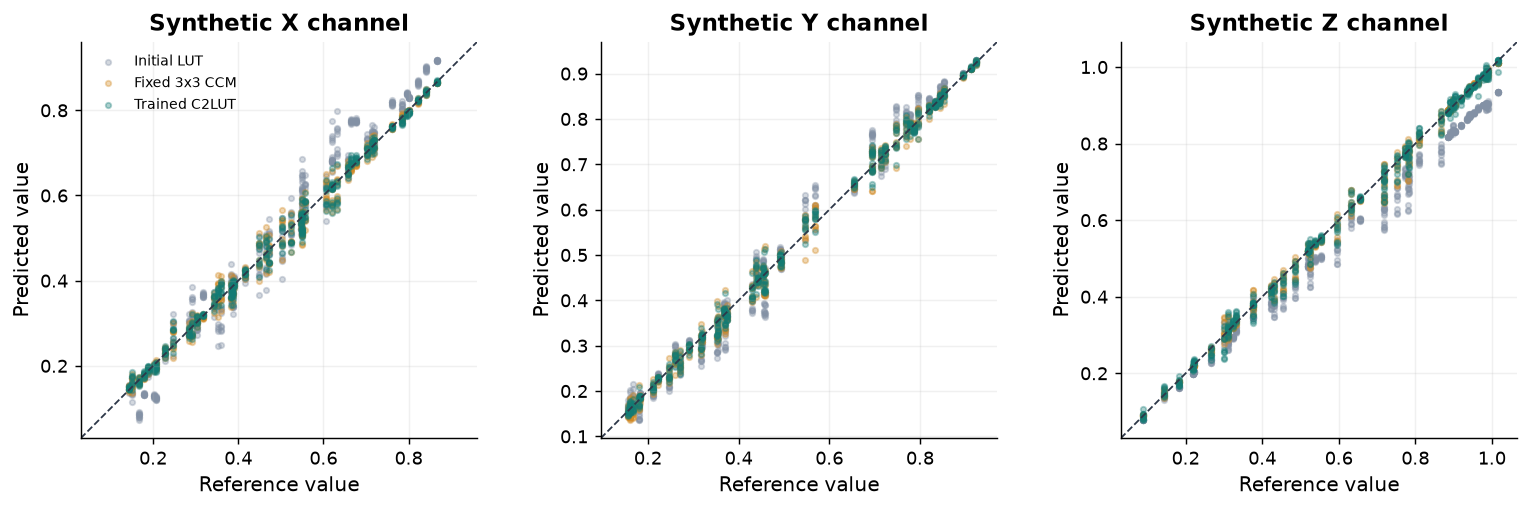

In [6]:
figure, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for channel, axis in enumerate(axes):
    for name in ("initial", "fixed_ccm", "trained"):
        axis.scatter(
            splits.test.xyz[..., channel].ravel(),
            predictions[name][..., channel].ravel(),
            s=9,
            alpha=0.35,
            color=palette[name],
            label=labels[name],
            rasterized=True,
        )
    all_values = np.concatenate(
        [
            splits.test.xyz[..., channel].ravel(),
            *[prediction[..., channel].ravel() for prediction in predictions.values()],
        ]
    )
    low, high = float(all_values.min()), float(all_values.max())
    padding = 0.05 * (high - low)
    limits = (low - padding, high + padding)
    axis.plot(limits, limits, "--", color="#2D3748", linewidth=1)
    axis.set(
        xlabel="Reference value",
        ylabel="Predicted value",
        xlim=limits,
        ylim=limits,
        title=f"Synthetic {'XYZ'[channel]} channel",
    )
    axis.set_aspect("equal", adjustable="box")
axes[0].legend(fontsize=8)
show_figure(figure, "04_channel_parity.png")

## 5. 同じ反射率を、異なる光源で見る

試験光源をカメラ r の小・中・大の順に 3 個選び、同じ 18 反射率を並べます。
各列は同一反射率、行は Reference / 白色化カメラ RGB / 固定 CCM / C²LUT です。
選択は誤差の大小を使わずに行います。

**表示の規約：** Reference・CCM・C²LUT は、合成 XYZ 相当値を sRGB の行列と伝達関数で
画面向けに可視化します。白色化カメラ RGB は、未較正の 3 チャネルをそのまま RGB と見なした
診断用の表示です。両者は同じ入力色空間ではありません。表示用 RGB の範囲外は `[0, 1]` に
切り詰めますが、この処理は学習・数値評価には使いません。

行列・伝達関数の出典：
[W3C CSS Color 4, Sample code for Color Conversions](https://www.w3.org/TR/2026/CRD-css-color-4-20260331/#color-conversion-code)。
見た目の類似だけで性能を判断せず、前節の色差と併せて見てください。

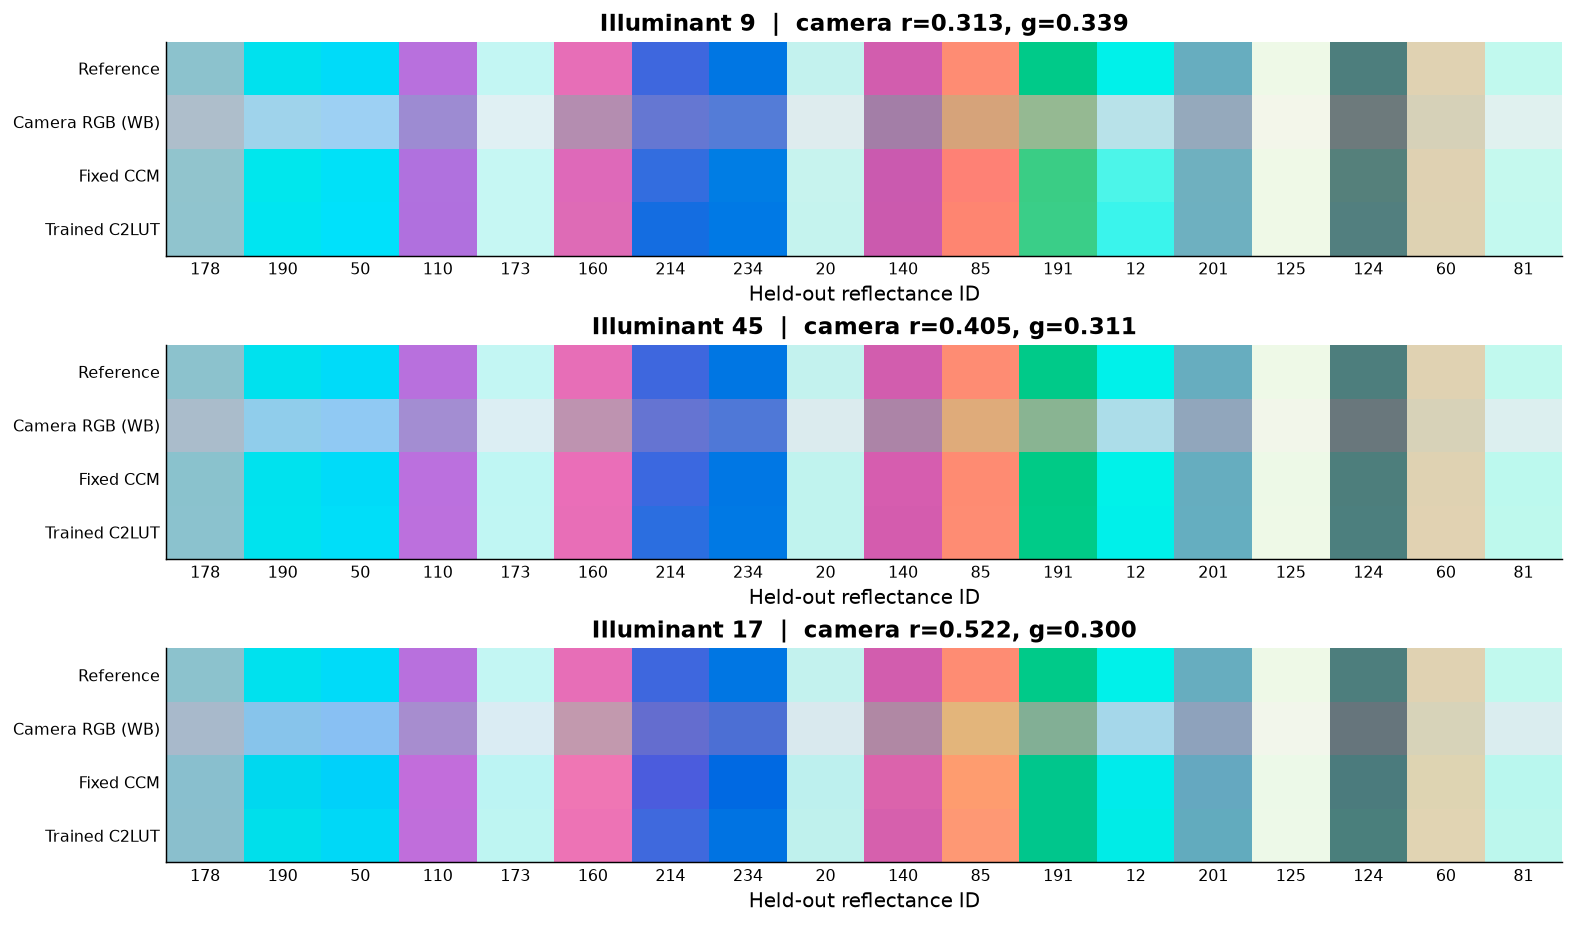

**表示時に切り詰めた RGB 成分の割合（全 test 組）：** reference: 8.33% / camera_rgb_wb: 0.00% / fixed_ccm: 6.39% / trained: 6.81%

In [7]:
xyz_to_linear_srgb = np.array(
    [
        [12831 / 3959, -329 / 214, -1974 / 3959],
        [-851781 / 878810, 1648619 / 878810, 36519 / 878810],
        [705 / 12673, -2585 / 12673, 705 / 667],
    ],
    dtype=np.float64,
)


def encode_display_rgb(linear_rgb: FloatArray) -> FloatArray:
    """Clip and encode for the screen only; never use this function for metrics."""
    clipped = np.clip(linear_rgb, 0.0, 1.0)
    return np.asarray(
        np.where(clipped <= 0.0031308, 12.92 * clipped, 1.055 * clipped ** (1.0 / 2.4) - 0.055)
    )


def display_xyz(xyz: FloatArray) -> FloatArray:
    """Illustrate synthetic XYZ-like triples using the sRGB display transform."""
    return encode_display_rgb(xyz @ xyz_to_linear_srgb.T)


test_rg = splits.test.white_points[:, :2] / splits.test.white_points.sum(axis=1, keepdims=True)
illuminant_order = np.argsort(test_rg[:, 0])
chosen_illuminants = illuminant_order[[0, len(illuminant_order) // 2, -1]]
patch_indices = np.linspace(0, splits.test.raw.shape[1] - 1, 18, dtype=int)
figure, axes = plt.subplots(3, 1, figsize=(12, 7), layout="constrained")
for axis, illuminant in zip(axes, chosen_illuminants, strict=True):
    patch_rows = np.stack(
        [
            display_xyz(splits.test.xyz[illuminant, patch_indices]),
            encode_display_rgb(test_balanced[illuminant, patch_indices]),
            display_xyz(predictions["fixed_ccm"][illuminant, patch_indices]),
            display_xyz(predictions["trained"][illuminant, patch_indices]),
        ]
    )
    axis.imshow(patch_rows, interpolation="nearest", aspect="auto")
    axis.set_yticks(range(4), ["Reference", "Camera RGB (WB)", "Fixed CCM", "Trained C2LUT"])
    axis.set_xticks(range(len(patch_indices)), splits.test.reflectance_ids[patch_indices])
    axis.set(
        xlabel="Held-out reflectance ID",
        title=f"Illuminant {splits.test.illuminant_ids[illuminant]}  |  "
        f"camera r={test_rg[illuminant, 0]:.3f}, g={test_rg[illuminant, 1]:.3f}",
    )
    axis.grid(False)
    axis.tick_params(axis="both", length=0, labelsize=9)
show_figure(figure, "05_color_patches.png")

display_linear_rows = {
    "reference": splits.test.xyz @ xyz_to_linear_srgb.T,
    "camera_rgb_wb": test_balanced,
    "fixed_ccm": predictions["fixed_ccm"] @ xyz_to_linear_srgb.T,
    "trained": predictions["trained"] @ xyz_to_linear_srgb.T,
}
clipped_fractions = {}
for name, display_linear in display_linear_rows.items():
    clipped_fractions[name] = float(np.mean((display_linear < 0) | (display_linear > 1)))
display(
    Markdown(
        "**表示時に切り詰めた RGB 成分の割合（全 test 組）：** "
        + " / ".join(f"{name}: {fraction:.2%}" for name, fraction in clipped_fractions.items())
    )
)

## 6. 光源に応じて変換が変わるか

学習前の混合重みは全基底で一様です。左図は、学習後の各基底の重みを光源ごとに表示します。
右図は、光源順に並べた同じ重みのヒートマップです。全重みが非負で、光源ごとの和が 1 になることも確認します。
ここでの spread は、基底ごとの「光源間の最大値 − 最小値」の最大です。

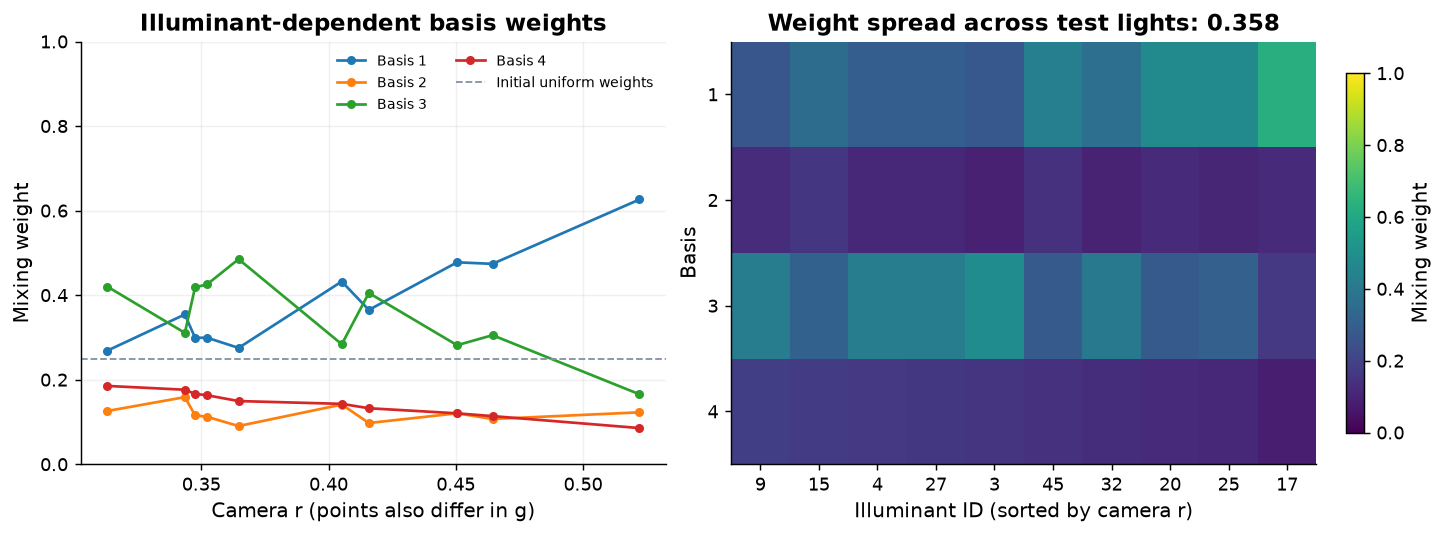

In [8]:
basis_weights = trained_model.weights(splits.test.white_points)
np.testing.assert_allclose(basis_weights.sum(axis=1), 1.0, atol=1e-12)
assert np.all(basis_weights >= 0)
basis_weight_spread = float(np.max(np.ptp(basis_weights, axis=0)))
figure, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for basis in range(model_config.num_bases):
    axes[0].plot(
        test_rg[illuminant_order, 0],
        basis_weights[illuminant_order, basis],
        "o-",
        linewidth=1.5,
        markersize=4,
        label=f"Basis {basis + 1}",
    )
axes[0].axhline(
    1 / model_config.num_bases,
    color="#8391A5",
    linestyle="--",
    linewidth=1,
    label="Initial uniform weights",
)
axes[0].set(
    xlabel="Camera r (points also differ in g)",
    ylabel="Mixing weight",
    title="Illuminant-dependent basis weights",
    ylim=(0, 1),
)
axes[0].legend(fontsize=8, ncols=2)
heatmap = axes[1].imshow(
    basis_weights[illuminant_order].T,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1,
    interpolation="nearest",
)
axes[1].set_xticks(range(len(illuminant_order)), splits.test.illuminant_ids[illuminant_order])
axes[1].set_yticks(range(model_config.num_bases), range(1, model_config.num_bases + 1))
axes[1].set(
    xlabel="Illuminant ID (sorted by camera r)",
    ylabel="Basis",
    title=f"Weight spread across test lights: {basis_weight_spread:.3f}",
)
axes[1].grid(False)
figure.colorbar(heatmap, ax=axes[1], label="Mixing weight", shrink=0.85)
show_figure(figure, "06_basis_weights.png")

### LUT の断面を見る

B = 0.5 の断面で、入力 R・G に対する出力 Y を表示します。
左・中央はカメラ r が最小・最大の試験光源で、**同じカラースケール**を使います。
右は両者の差です。LUT 全域の診断用表示であり、この格子上の全入力に教師データがあるわけではありません。

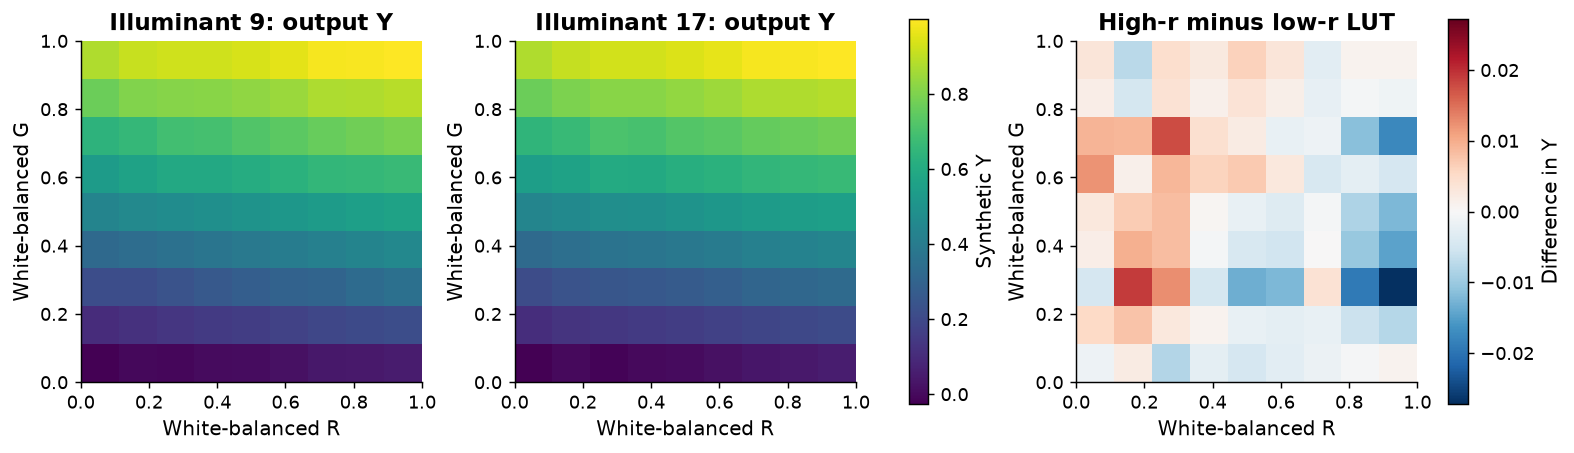

In [9]:
low_illuminant, high_illuminant = illuminant_order[[0, -1]]
blue_index = model_config.grid_size // 2
low_slice = trained_model.make_lut(splits.test.white_points[low_illuminant])[1, :, :, blue_index].T
high_slice = trained_model.make_lut(splits.test.white_points[high_illuminant])[
    1, :, :, blue_index
].T
difference = high_slice - low_slice
common_min = float(min(low_slice.min(), high_slice.min()))
common_max = float(max(low_slice.max(), high_slice.max()))
difference_max = max(float(np.abs(difference).max()), 1e-12)
figure, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for axis, surface, illuminant in zip(
    axes[:2], (low_slice, high_slice), (low_illuminant, high_illuminant), strict=True
):
    surface_image = axis.imshow(
        surface,
        origin="lower",
        extent=(0, 1, 0, 1),
        vmin=common_min,
        vmax=common_max,
        cmap="viridis",
    )
    axis.set(
        title=f"Illuminant {splits.test.illuminant_ids[illuminant]}: output Y",
        xlabel="White-balanced R",
        ylabel="White-balanced G",
    )
    axis.grid(False)
figure.colorbar(surface_image, ax=list(axes[:2]), label="Synthetic Y", shrink=0.8)
difference_image = axes[2].imshow(
    difference,
    origin="lower",
    extent=(0, 1, 0, 1),
    cmap="RdBu_r",
    vmin=-difference_max,
    vmax=difference_max,
)
axes[2].set(title="High-r minus low-r LUT", xlabel="White-balanced R", ylabel="White-balanced G")
axes[2].grid(False)
figure.colorbar(difference_image, ax=axes[2], label="Difference in Y", shrink=0.8)
show_figure(figure, "07_lut_slices.png")

## 7. 保存・再読込みと C++ 推論の照合

最良モデルを数値配列だけの NPZ へ保存し、読み戻して全 test 組を再評価します。
同じモデルの PyTorch 出力とも照合します。ここまでの推論は `c2lut._native` を使っており、
NumPy の参照補間への暗黙の切替えはありません。

既定 seed の実験では、初期状態より平均 ΔE76 が半分未満になり、固定 CCM よりも小さくなることを
E2E テストで確認します。seed・データ数・更新回数を変えた場合に同じ改善量を保証するものではありません。
下のセルは数値整合性を検証し、指標と設定を `metrics.json` に保存します。

In [10]:
trained_model.save(artifact_dir / "model.npz")
reloaded_model = C2LUT.load(artifact_dir / "model.npz")
reloaded_prediction = predict_dataset(reloaded_model, splits.test)
reload_max_abs_error = float(np.max(np.abs(reloaded_prediction - predictions["trained"])))
with torch.no_grad():
    torch_prediction = (
        trainable(
            torch.tensor(splits.test.raw.copy(), dtype=torch.float64),
            torch.tensor(splits.test.white_points.copy(), dtype=torch.float64),
        )
        .cpu()
        .numpy()
    )
native_torch_max_abs_error = float(np.max(np.abs(torch_prediction - predictions["trained"])))
np.testing.assert_array_equal(reloaded_prediction, predictions["trained"])
np.testing.assert_allclose(torch_prediction, predictions["trained"], rtol=1e-11, atol=1e-12)
assert all(np.all(np.isfinite(prediction)) for prediction in predictions.values())

report = {
    "seed": SEED,
    "training_steps": TRAINING_STEPS,
    "best_step": training_result.best_step,
    "model_config": asdict(model_config),
    "training_config": asdict(training_config),
    "split_shapes": {name: list(dataset.raw.shape) for name, dataset in datasets.items()},
    "metrics": metrics,
    "reload_max_abs_error": reload_max_abs_error,
    "native_torch_max_abs_error": native_torch_max_abs_error,
    "native_backend": _native.__name__,
    "basis_weight_spread": basis_weight_spread,
    "display_clipped_component_fractions": clipped_fractions,
    "figure_files": figure_files,
    "versions": versions,
    "dataset_kind": "artificial observer and spectra; XYZ-like synthetic coordinates",
    "selection": "minimum validation Delta E76; test data excluded from fitting and selection",
}
(artifact_dir / "metrics.json").write_text(
    json.dumps(report, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8"
)
improvement = 1.0 - metrics["trained"]["delta_e76_mean"] / metrics["initial"]["delta_e76_mean"]
display(
    Markdown(
        f"**test の平均 ΔE76：{metrics['initial']['delta_e76_mean']:.3f} → "
        f"{metrics['trained']['delta_e76_mean']:.3f}（初期値から {improvement:.1%} 低下）**\n\n"
        f"保存前後の最大絶対差：`{reload_max_abs_error:.3e}` / "
        f"C++ と PyTorch の最大絶対差：`{native_torch_max_abs_error:.3e}`\n\n"
        f"保存済み：`train.npz`, `validation.npz`, `test.npz`, `model.npz`, `metrics.json`, "
        f"`figures/` の {len(figure_files)} 図。"
    )
)

**test の平均 ΔE76：18.425 → 2.155（初期値から 88.3% 低下）**

保存前後の最大絶対差：`0.000e+00` / C++ と PyTorch の最大絶対差：`3.331e-16`

保存済み：`train.npz`, `validation.npz`, `test.npz`, `model.npz`, `metrics.json`, `figures/` の 7 図。

## 次に確認すること

seed・光源数・反射率数・モデル規模を変える場合は、必ずカーネルを再起動して全セルを実行してください。
全 test 組の平均が改善しても、全ての反射率・光源で個別に改善するとは限りません。
異なる条件へ一般化できるかは、分布図・光源別誤差・色差分布を合わせて判断します。
実データに進む場合は、`render_spectra` に同じ波長格子の実測感度・光源・反射率・等色関数を渡して
データセットを用意し、カメラ RGB と白色点の尺度を揃えてください。

- [実装の数値規約と論文との差分](../docs/method.md)
- [論文：Illuminant-Adaptive 3D Lookup Tables for Camera Color Correction](https://arxiv.org/abs/2607.11681)

Notebook を新しいカーネルで実行する自動テスト：

```bash
uv run --locked --extra notebook pytest -q -m notebook
```